# Clasificación de tejido histopatológico con Deep Learning (PathMNIST)

**Autora:** Miriam Alicia Velazque — Técnica Superior en Ciencia de Datos e IA (CPMA, Río Grande, TDF)

## Objetivo
Clasificar imágenes de tejido de colon teñidas con hematoxilina-eosina (H&E) en **9 tipos de tejido**, combinando:

1. **Procesamiento digital clásico** (espacios de color, umbral de Otsu, morfología) para analizar el contenido de las imágenes.
2. **Transfer learning** con **MobileNetV2** preentrenada en ImageNet, en dos etapas (extractor congelado + fine-tuning).
3. **Validación** con métricas por clase y matriz de confusión sobre un conjunto de test de **otro centro clínico**.
4. **Interpretabilidad** con **Grad-CAM**: mapas de calor que muestran qué zonas de la imagen usó el modelo para decidir.

## Datos
[PathMNIST](https://medmnist.com/) (parte de MedMNIST v2), derivado de los datasets NCT-CRC-HE-100K (entrenamiento/validación) y CRC-VAL-HE-7K (test) de Kather et al. Licencia CC BY 4.0.
Se usa la versión de **64×64 px**.

> ⚙️ Antes de correr: **Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)**.

In [1]:
!pip install -q medmnist

## 1. Configuración

In [2]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA_SIZE   = 64      # resolución de PathMNIST que se descarga
MODEL_SIZE  = 96      # resolución de entrada a MobileNetV2 (funciona mejor con imágenes no tan chicas)
BATCH       = 128     # la red procesa las imágenes de a 128 por vez
N_TRAIN     = 30000   # submuestra estratificada de train (None = usar las ~90.000)imágenes de entrenamiento se usan 30.000 para que tarde menos
EPOCHS_HEAD = 6       # cantidad de pasadas de cada etapa de entrenamiento
EPOCHS_FT   = 6       # cantidad de pasadas de cada etapa de entrenamiento

OUT = "resultados"
os.makedirs(OUT, exist_ok=True)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Carga de datos

In [3]:
from medmnist import PathMNIST, INFO

info = INFO["pathmnist"]
splits = {s: PathMNIST(split=s, download=True, size=DATA_SIZE) for s in ["train", "val", "test"]}

x_train, y_train = splits["train"].imgs, splits["train"].labels.ravel()
x_val,   y_val   = splits["val"].imgs,   splits["val"].labels.ravel()
x_test,  y_test  = splits["test"].imgs,  splits["test"].labels.ravel()

# Nombres de clase en español (orden oficial de PathMNIST)
CLASES = [
    "Tejido adiposo",            # adipose
    "Fondo",                     # background
    "Detritos",                  # debris
    "Linfocitos",                # lymphocytes
    "Mucus",                     # mucus
    "Músculo liso",              # smooth muscle
    "Mucosa colónica normal",    # normal colon mucosa
    "Estroma asociado a cáncer", # cancer-associated stroma
    "Epitelio de adenocarcinoma" # colorectal adenocarcinoma epithelium
]
N_CLASES = len(CLASES)
print("Etiquetas originales:", info["label"])
print(f"train {x_train.shape} | val {x_val.shape} | test {x_test.shape} | dtype {x_train.dtype}")

100%|██████████| 1.07G/1.07G [06:41<00:00, 2.66MB/s]


Etiquetas originales: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}
train (89996, 64, 64, 3) | val (10004, 64, 64, 3) | test (7180, 64, 64, 3) | dtype uint8


## 3. Análisis exploratorio

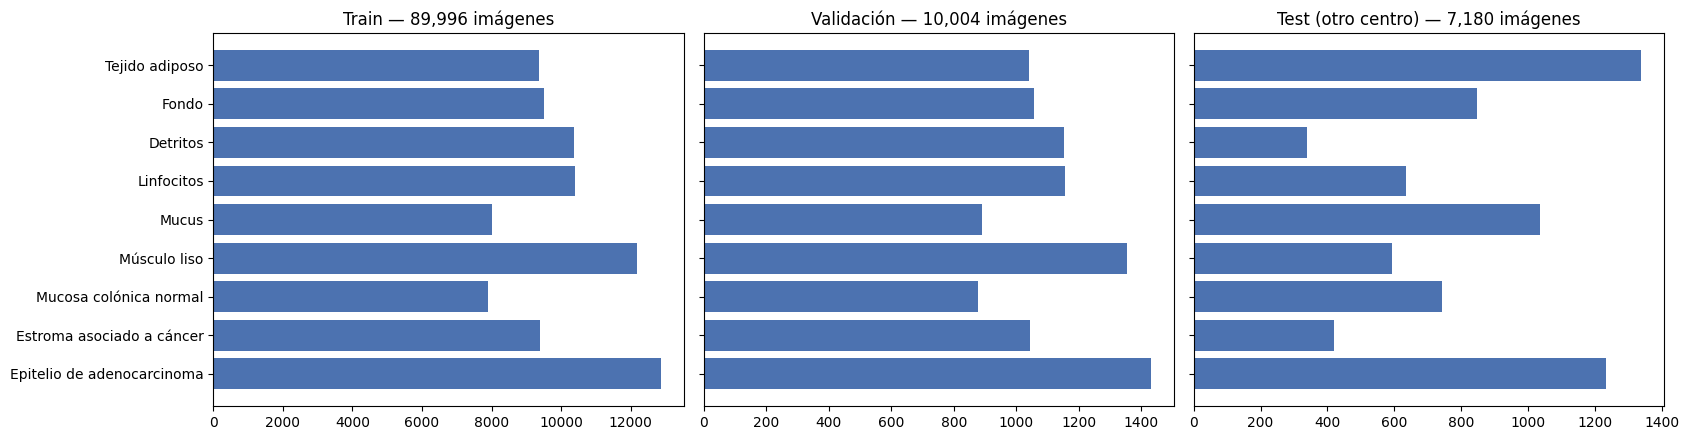

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=False)
for ax, (nombre, y) in zip(axes, [("Train", y_train), ("Validación", y_val), ("Test (otro centro)", y_test)]):
    conteo = np.bincount(y, minlength=N_CLASES)
    ax.barh(CLASES, conteo, color="#4C72B0")
    ax.set_title(f"{nombre} — {len(y):,} imágenes"); ax.invert_yaxis()
    if ax is not axes[0]: ax.set_yticklabels([])
plt.tight_layout(); plt.savefig(f"{OUT}/distribucion_clases.png", dpi=120); plt.show()

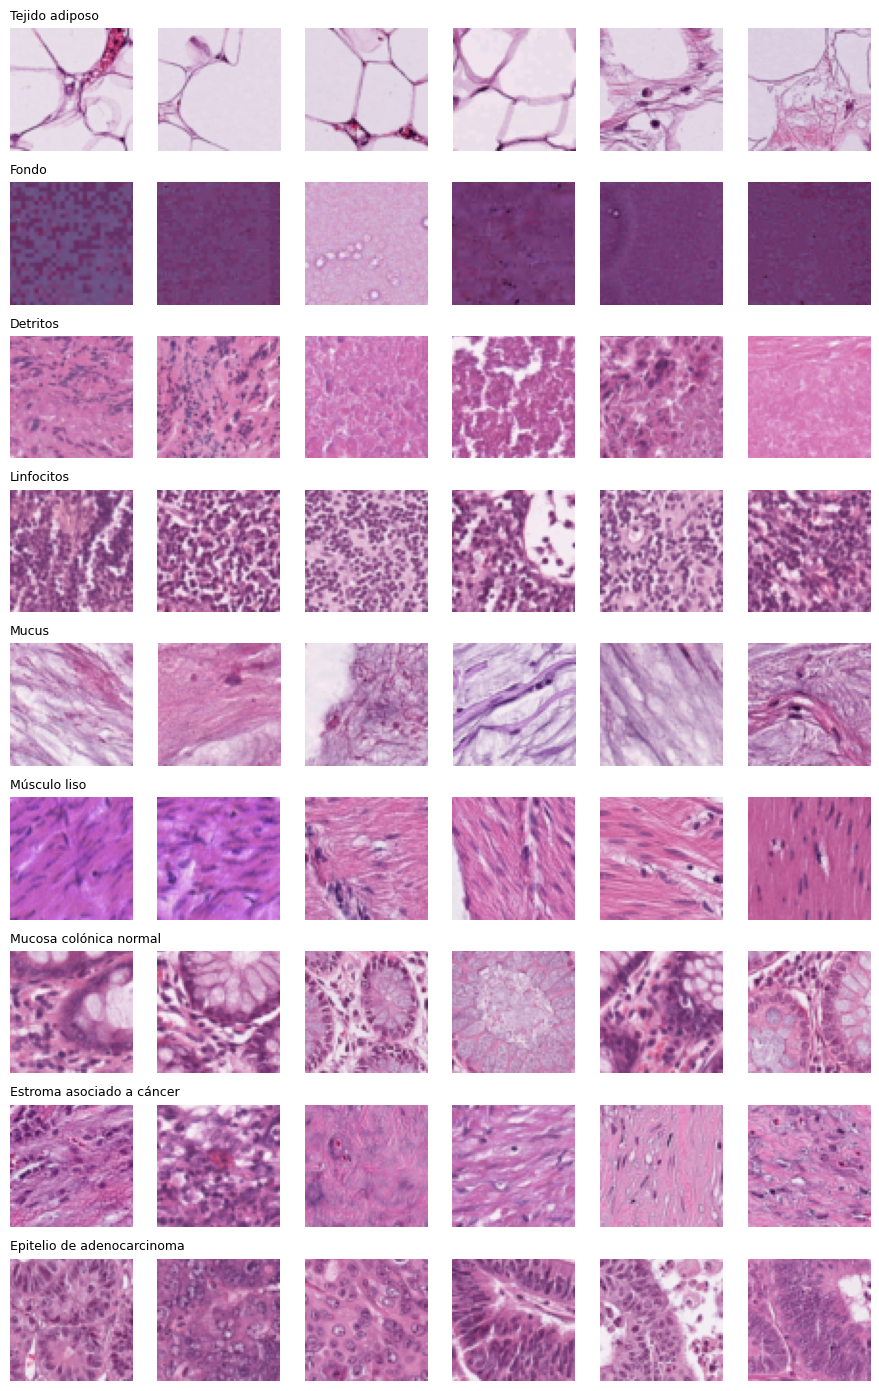

In [5]:
# 6 ejemplos por clase
fig, axes = plt.subplots(N_CLASES, 6, figsize=(9, 14))
for c in range(N_CLASES):
    idx = np.random.choice(np.where(y_train == c)[0], 6, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(x_train[i]); axes[c, j].axis("off")
    axes[c, 0].set_title(CLASES[c], fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT}/ejemplos_por_clase.png", dpi=120); plt.show()

### 3.1 Color medio por clase y diferencias entre centros
En H&E la hematoxilina tiñe núcleos (violeta/azul) y la eosina el citoplasma y el estroma (rosa). La variación de tinción entre laboratorios es uno de los principales problemas en patología digital, así que comparamos el color medio de train (centro A) y test (centro B).

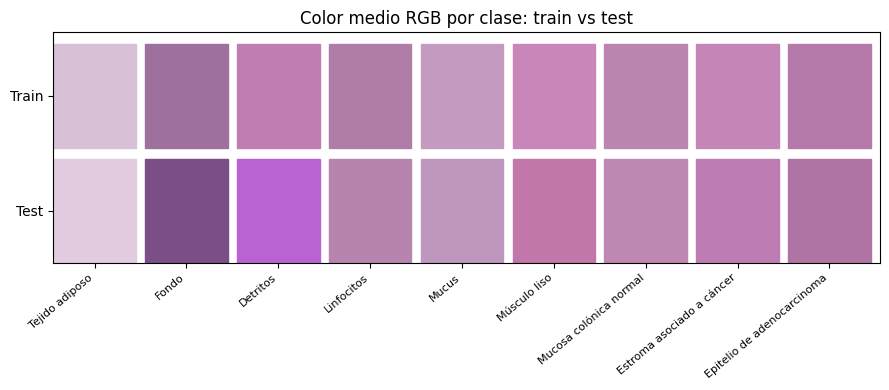

Diferencia media absoluta de color (0-255) entre centros: 10.8


In [6]:
def color_medio(x, y):
    return np.array([x[y == c].reshape(-1, 3).mean(0) for c in range(N_CLASES)]) / 255

cm_train, cm_test = color_medio(x_train, y_train), color_medio(x_test, y_test)
fig, ax = plt.subplots(figsize=(9, 4))
for c in range(N_CLASES):
    ax.add_patch(plt.Rectangle((c, 1), 0.9, 0.9, color=cm_train[c]))
    ax.add_patch(plt.Rectangle((c, 0), 0.9, 0.9, color=cm_test[c]))
ax.set_xlim(0, N_CLASES); ax.set_ylim(0, 2)
ax.set_yticks([0.45, 1.45]); ax.set_yticklabels(["Test", "Train"])
ax.set_xticks(np.arange(N_CLASES) + 0.45); ax.set_xticklabels(CLASES, rotation=40, ha="right", fontsize=8)
ax.set_title("Color medio RGB por clase: train vs test")
plt.tight_layout(); plt.savefig(f"{OUT}/color_medio_train_vs_test.png", dpi=120); plt.show()

print("Diferencia media absoluta de color (0-255) entre centros:", np.round(np.abs(cm_train - cm_test).mean() * 255, 1))

## 4. Procesamiento digital clásico: segmentación de tejido
Antes del deep learning aplicamos un pipeline clásico (equivalente a lo que se haría en ImageJ):
1. Conversión a **HSV** y uso del canal de **saturación** (el tejido teñido está saturado; el fondo/vidrio no).
2. **Umbral de Otsu** automático.
3. **Apertura morfológica** para eliminar ruido.
4. Cálculo del **% de área con tejido** por imagen.

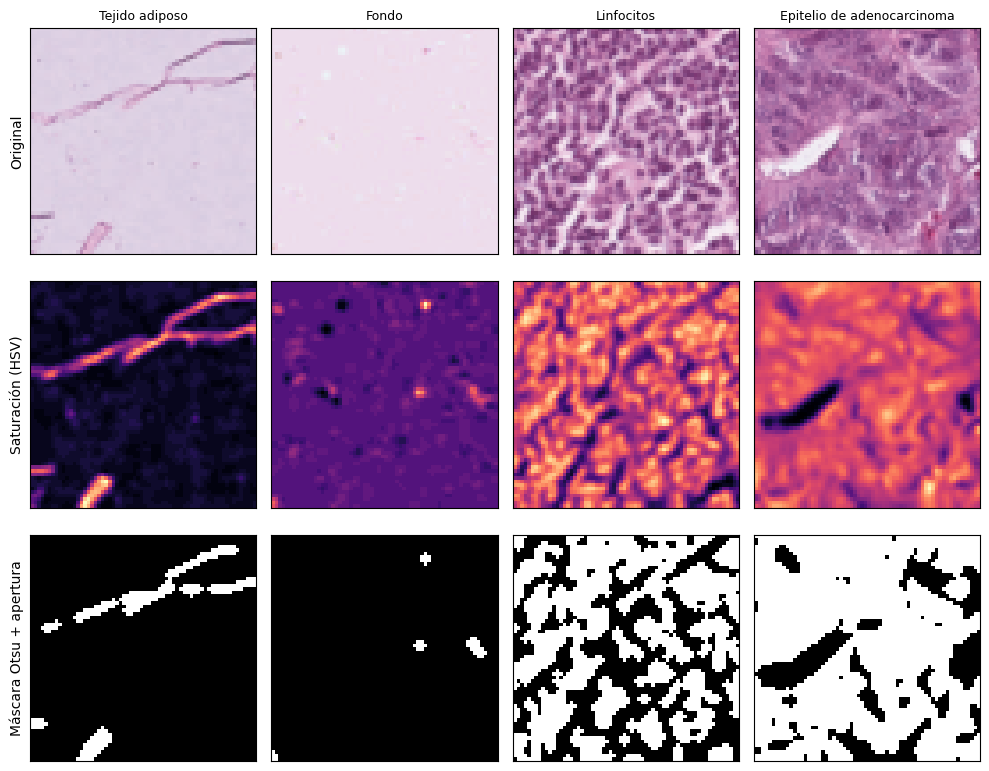

In [7]:
KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

def mascara_tejido(img_rgb):
    sat = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)[:, :, 1]
    sat = cv2.GaussianBlur(sat, (3, 3), 0)
    _, mask = cv2.threshold(sat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, KERNEL)
    return sat, mask

# Ejemplo visual
ejemplos = [np.where(y_train == c)[0][0] for c in [0, 1, 3, 8]]
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for j, i in enumerate(ejemplos):
    sat, mask = mascara_tejido(x_train[i])
    axes[0, j].imshow(x_train[i]); axes[0, j].set_title(CLASES[y_train[i]], fontsize=9)
    axes[1, j].imshow(sat, cmap="magma")
    axes[2, j].imshow(mask, cmap="gray")
for ax, t in zip(axes[:, 0], ["Original", "Saturación (HSV)", "Máscara Otsu + apertura"]):
    ax.set_ylabel(t)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(f"{OUT}/segmentacion_clasica.png", dpi=120); plt.show()

Umbral global de saturación (Otsu): 70.0


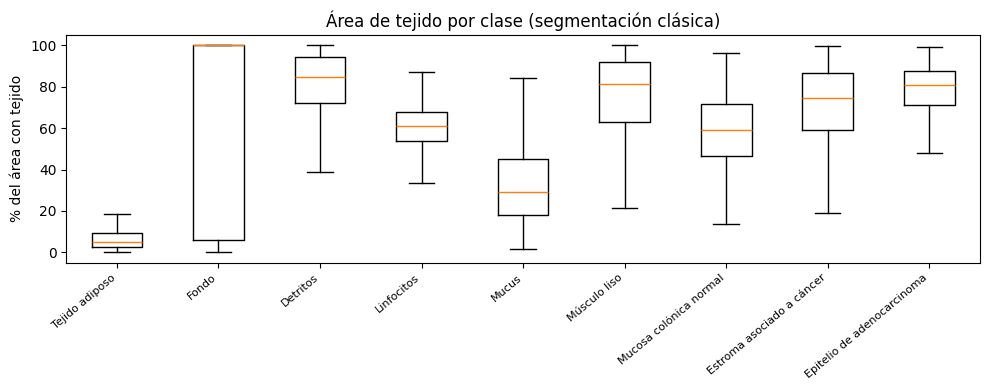

In [8]:
# % de tejido por clase (umbral de saturación fijo, calculado con Otsu sobre una muestra global)
muestra = x_train[np.random.choice(len(x_train), 3000, replace=False)]
sat_global = np.concatenate([cv2.cvtColor(im, cv2.COLOR_RGB2HSV)[:, :, 1].ravel() for im in muestra])
UMBRAL, _ = cv2.threshold(sat_global.reshape(1, -1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Umbral global de saturación (Otsu):", UMBRAL)

def pct_tejido(img):
    sat = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[:, :, 1]
    return (sat > UMBRAL).mean() * 100

pct = {c: [pct_tejido(x_train[i]) for i in np.where(y_train == c)[0][:500]] for c in range(N_CLASES)}
plt.figure(figsize=(10, 4))
plt.boxplot([pct[c] for c in range(N_CLASES)], showfliers=False)
plt.xticks(range(1, N_CLASES + 1), CLASES, rotation=40, ha="right", fontsize=8)
plt.ylabel("% del área con tejido"); plt.title("Área de tejido por clase (segmentación clásica)")
plt.tight_layout(); plt.savefig(f"{OUT}/area_tejido_por_clase.png", dpi=120); plt.show()

Lectura: la segmentación clásica identifica muy bien el tejido adiposo (poca área teñida), pero la clase Fondo resulta bimodal: incluye zonas claras (≈0 % de tejido) y zonas violetas o desenfocadas que superan el umbral de saturación (≈100 %). Además, detritos, músculo liso, estroma y epitelio tumoral se superponen en área teñida. Una sola característica de color no alcanza para clasificar tejidos: hace falta aprender texturas y patrones, y para eso usamos una CNN.

## 5. Preparación de datos para el modelo

In [9]:
# Submuestra estratificada de entrenamiento (para entrenar rápido en Colab)
if N_TRAIN and N_TRAIN < len(x_train):
    x_tr, _, y_tr, _ = train_test_split(x_train, y_train, train_size=N_TRAIN, stratify=y_train, random_state=SEED)
else:
    x_tr, y_tr = x_train, y_train
print("Imágenes de entrenamiento usadas:", len(x_tr))

AUTOTUNE = tf.data.AUTOTUNE

def preparar(img, label):
    img = tf.image.resize(tf.cast(img, tf.float32), (MODEL_SIZE, MODEL_SIZE))
    return img, label   # el escalado a [-1, 1] está dentro del modelo

def aumentar(img, label):
    # El tejido no tiene orientación: rotaciones de 90° y espejados son válidos
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    # Pequeña variación de brillo/contraste/saturación para simular diferencias de tinción
    img = tf.image.random_brightness(img, 20.0)
    img = tf.image.random_contrast(img, 0.85, 1.15)
    img = tf.image.random_saturation(img, 0.85, 1.15)
    return tf.clip_by_value(img, 0.0, 255.0), label

def dataset(x, y, entrenar=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if entrenar:
        ds = ds.shuffle(10000, seed=SEED)
    ds = ds.map(preparar, num_parallel_calls=AUTOTUNE)
    if entrenar:
        ds = ds.map(aumentar, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

ds_train = dataset(x_tr, y_tr, entrenar=True)
ds_val   = dataset(x_val, y_val)
ds_test  = dataset(x_test, y_test)

Imágenes de entrenamiento usadas: 30000


## 6. Modelo: MobileNetV2 + transfer learning
Se construye todo en un único grafo (sin submodelos anidados) para poder aplicar Grad-CAM sobre la última capa convolucional (`out_relu`).

In [10]:
def construir_modelo(pesos="imagenet"):
    entrada = keras.Input((MODEL_SIZE, MODEL_SIZE, 3), name="imagen")
    x = layers.Rescaling(1 / 127.5, offset=-1, name="escala_mobilenet")(entrada)
    base = keras.applications.MobileNetV2(include_top=False, weights=pesos, input_tensor=x)
    base.trainable = False
    x = layers.GlobalAveragePooling2D(name="gap")(base.output)
    x = layers.Dropout(0.3, name="dropout")(x)
    salida = layers.Dense(N_CLASES, activation="softmax", name="clasificador")(x)
    return keras.Model(entrada, salida, name="pathmnist_mobilenetv2"), base

modelo, base = construir_modelo()
print(f"Parámetros totales: {modelo.count_params():,} | entrenables: {sum(np.prod(w.shape) for w in modelo.trainable_weights):,}")

/tmp/ipykernel_338/3712639963.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(include_top=False, weights=pesos, input_tensor=x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parámetros totales: 2,269,513 | entrenables: 11,529


### 6.1 Etapa 1 — entrenar solo el clasificador (base congelada)

In [11]:
modelo.compile(optimizer=keras.optimizers.Adam(1e-3),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=2, restore_best_weights=True)]
hist1 = modelo.fit(ds_train, validation_data=ds_val, epochs=EPOCHS_HEAD, callbacks=cb)

Epoch 1/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 73s 210ms/step - accuracy: 0.5970 - loss: 1.2310 - val_accuracy: 0.7977 - val_loss: 0.5972
Epoch 2/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 15s 64ms/step - accuracy: 0.7517 - loss: 0.7298 - val_accuracy: 0.8182 - val_loss: 0.5291
Epoch 3/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 20s 62ms/step - accuracy: 0.7835 - loss: 0.6415 - val_accuracy: 0.8205 - val_loss: 0.5033
Epoch 4/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 15s 62ms/step - accuracy: 0.7952 - loss: 0.5914 - val_accuracy: 0.8461 - val_loss: 0.4577
Epoch 5/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 14s 61ms/step - accuracy: 0.8039 - loss: 0.5792 - val_accuracy: 0.8419 - val_loss: 0.4694
Epoch 6/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 21s 65ms/step - accuracy: 0.8045 - loss: 0.5673 - val_accuracy: 0.8346 - val_loss: 0.4660


### 6.2 Etapa 2 — fine-tuning de las últimas capas

In [12]:
N_DESCONGELAR = 40
for capa in base.layers[-N_DESCONGELAR:]:
    if not isinstance(capa, layers.BatchNormalization):   # BatchNorm queda congelada
        capa.trainable = True

modelo.compile(optimizer=keras.optimizers.Adam(1e-5),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=2, restore_best_weights=True),
      keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1)]
hist2 = modelo.fit(ds_train, validation_data=ds_val, epochs=EPOCHS_FT, callbacks=cb)

Epoch 1/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 46s 129ms/step - accuracy: 0.8443 - loss: 0.4506 - val_accuracy: 0.8819 - val_loss: 0.3361 - learning_rate: 1.0000e-05
Epoch 2/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step - accuracy: 0.8748 - loss: 0.3627 - val_accuracy: 0.8947 - val_loss: 0.2971 - learning_rate: 1.0000e-05
Epoch 3/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - accuracy: 0.8849 - loss: 0.3312 - val_accuracy: 0.9062 - val_loss: 0.2725 - learning_rate: 1.0000e-05
Epoch 4/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 16s 68ms/step - accuracy: 0.8951 - loss: 0.3033 - val_accuracy: 0.9110 - val_loss: 0.2619 - learning_rate: 1.0000e-05
Epoch 5/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step - accuracy: 0.9009 - loss: 0.2862 - val_accuracy: 0.9109 - val_loss: 0.2531 - learning_rate: 1.0000e-05
Epoch 6/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step - accuracy: 0.9088 - loss: 0.2663 - val_accuracy: 0.9193 - val_loss: 0.2344 - learning_rate: 1.0000e-05


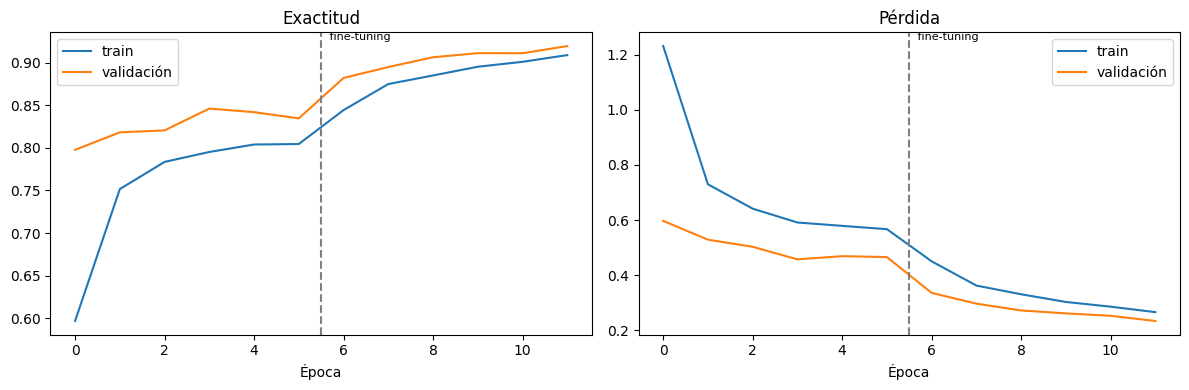

In [13]:
def unir(h1, h2, k): return h1.history[k] + h2.history[k]
ep1 = len(hist1.history["loss"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k, t in zip(axes, ["accuracy", "loss"], ["Exactitud", "Pérdida"]):
    ax.plot(unir(hist1, hist2, k), label="train")
    ax.plot(unir(hist1, hist2, "val_" + k), label="validación")
    ax.axvline(ep1 - 0.5, ls="--", c="gray"); ax.text(ep1 - 0.4, ax.get_ylim()[1], " fine-tuning", va="top", fontsize=8)
    ax.set_title(t); ax.set_xlabel("Época"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/curvas_entrenamiento.png", dpi=120); plt.show()

## 7. Evaluación
El test de PathMNIST viene de otro centro clínico (CRC-VAL-HE-7K), con tinción y escáner distintos, así que mide cómo generalizaría el modelo a un laboratorio nuevo.

In [14]:
prob_val  = modelo.predict(ds_val, verbose=0)
prob_test = modelo.predict(ds_test, verbose=0)
pred_val, pred_test = prob_val.argmax(1), prob_test.argmax(1)

acc_val, acc_test = accuracy_score(y_val, pred_val), accuracy_score(y_test, pred_test)
print(f"Exactitud validación (mismo centro): {acc_val:.3f}")
print(f"Exactitud test (otro centro):        {acc_test:.3f}\n")
print(classification_report(y_test, pred_test, target_names=CLASES, digits=3, zero_division=0))

Exactitud validación (mismo centro): 0.919
Exactitud test (otro centro):        0.918

                            precision    recall  f1-score   support

            Tejido adiposo      0.988     0.989     0.988      1338
                     Fondo      0.991     0.996     0.994       847
                  Detritos      0.786     0.920     0.848       339
                Linfocitos      0.957     0.989     0.973       634
                     Mucus      0.972     0.959     0.965      1035
              Músculo liso      0.719     0.875     0.790       592
    Mucosa colónica normal      0.925     0.901     0.913       741
 Estroma asociado a cáncer      0.723     0.466     0.566       421
Epitelio de adenocarcinoma      0.923     0.899     0.911      1233

                  accuracy                          0.918      7180
                 macro avg      0.887     0.888     0.883      7180
              weighted avg      0.918     0.918     0.915      7180



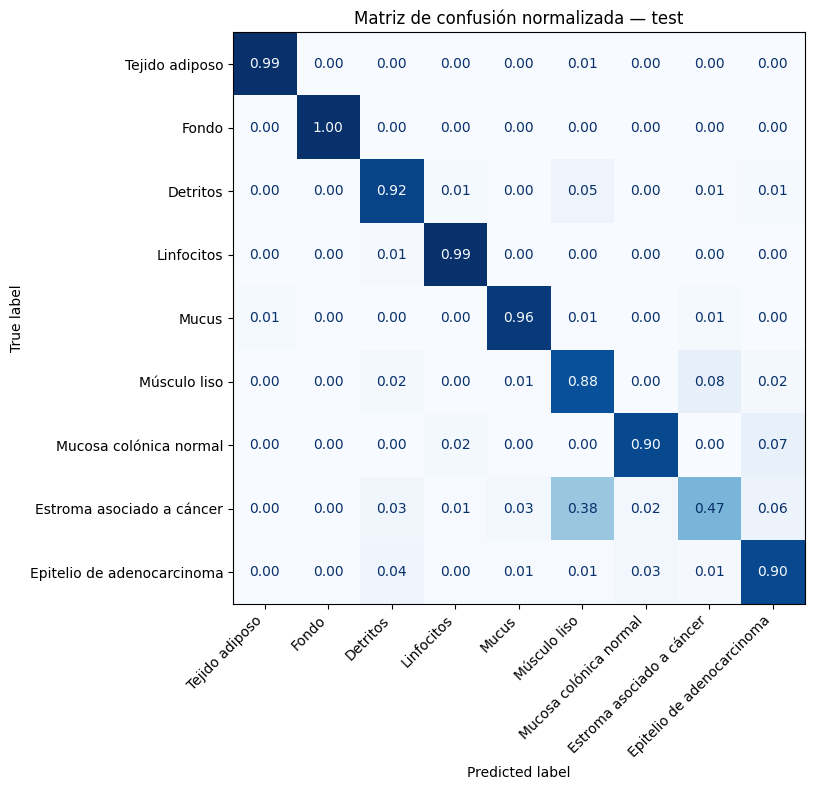

In [15]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test, normalize="true"),
                       display_labels=CLASES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
plt.xticks(rotation=45, ha="right"); ax.set_title("Matriz de confusión normalizada — test")
plt.tight_layout(); plt.savefig(f"{OUT}/matriz_confusion.png", dpi=120); plt.show()

## 8. Interpretabilidad con Grad-CAM
Grad-CAM calcula cuánto influye cada zona de la última capa convolucional en la clase predicha y lo proyecta como mapa de calor sobre la imagen. Sirve para validar que el modelo mira estructuras con sentido (núcleos, glándulas, fibras) y no artefactos.

In [16]:
modelo_gradcam = keras.Model(modelo.inputs, [modelo.get_layer("out_relu").output, modelo.output])

def gradcam(img_uint8, clase=None):
    x = tf.image.resize(tf.cast(img_uint8[None], tf.float32), (MODEL_SIZE, MODEL_SIZE))
    with tf.GradientTape() as tape:
        mapas, prob = modelo_gradcam(x, training=False)
        if clase is None:
            clase = int(tf.argmax(prob[0]))
        puntaje = prob[:, clase]
    grads = tape.gradient(puntaje, mapas)
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(mapas[0] * pesos, axis=-1)).numpy()
    cam = cam / (cam.max() + 1e-8)
    cam = cv2.resize(cam, (img_uint8.shape[1], img_uint8.shape[0]))
    return cam, clase, float(prob[0, clase])

def superponer(img, cam, alpha=0.4):
    calor = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[:, :, ::-1]
    return np.uint8((1 - alpha) * img + alpha * calor)

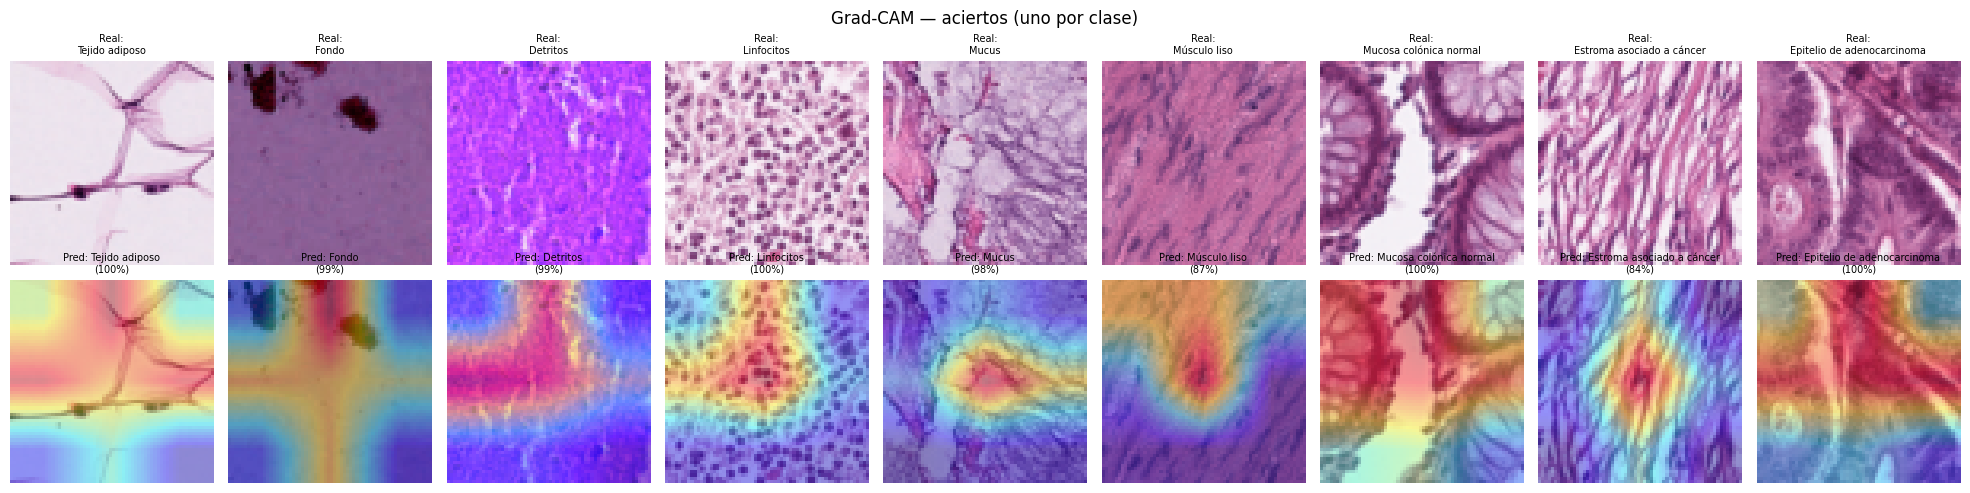

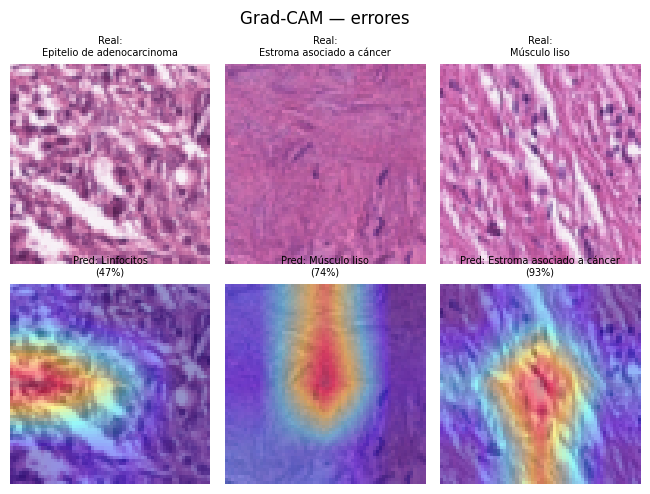

In [17]:
# Un acierto por clase + algunos errores
aciertos = [np.where((y_test == c) & (pred_test == c))[0][0] for c in range(N_CLASES)
            if np.any((y_test == c) & (pred_test == c))]
errores = np.where(y_test != pred_test)[0][:3]

def grilla(indices, titulo, archivo):
    fig, axes = plt.subplots(2, len(indices), figsize=(2.2 * len(indices), 5))
    axes = np.array(axes).reshape(2, -1)
    for j, i in enumerate(indices):
        cam, c, p = gradcam(x_test[i])
        axes[0, j].imshow(x_test[i]); axes[0, j].set_title(f"Real:\n{CLASES[y_test[i]]}", fontsize=7)
        axes[1, j].imshow(superponer(x_test[i], cam)); axes[1, j].set_title(f"Pred: {CLASES[c]}\n({p:.0%})", fontsize=7)
    for ax in axes.ravel(): ax.axis("off")
    fig.suptitle(titulo); plt.tight_layout(); plt.savefig(f"{OUT}/{archivo}", dpi=120); plt.show()

grilla(aciertos, "Grad-CAM — aciertos (uno por clase)", "gradcam_aciertos.png")
if len(errores):
    grilla(list(errores), "Grad-CAM — errores", "gradcam_errores.png")

## 9. Guardar modelo y resumen de resultados

In [18]:
modelo.save("modelo_pathmnist.keras")

f1 = classification_report(y_test, pred_test, target_names=CLASES, output_dict=True, zero_division=0)
resumen = f'''
RESULTADOS PARA EL README
- Imágenes de entrenamiento: {len(x_tr):,} (de {len(x_train):,})
- Exactitud validación (mismo centro): {acc_val:.1%}
- Exactitud test (otro centro): {acc_test:.1%}
- F1 macro test: {f1["macro avg"]["f1-score"]:.3f}
- Mejor clase (F1): {max(CLASES, key=lambda c: f1[c]["f1-score"])}
- Peor clase (F1): {min(CLASES, key=lambda c: f1[c]["f1-score"])}
'''
print(resumen)
open(f"{OUT}/resumen.txt", "w", encoding="utf-8").write(resumen)

# Un parche de test por clase, para probar la demo de Streamlit
import unicodedata
os.makedirs(f"{OUT}/ejemplos", exist_ok=True)
for c in range(N_CLASES):
    i = np.where(y_test == c)[0][0]
    nombre = unicodedata.normalize("NFKD", CLASES[c]).encode("ascii", "ignore").decode().replace(" ", "_")
    cv2.imwrite(f"{OUT}/ejemplos/{c}_{nombre}.png", cv2.cvtColor(x_test[i], cv2.COLOR_RGB2BGR))


RESULTADOS PARA EL README
- Imágenes de entrenamiento: 30,000 (de 89,996)
- Exactitud validación (mismo centro): 91.9%
- Exactitud test (otro centro): 91.8%
- F1 macro test: 0.883
- Mejor clase (F1): Fondo
- Peor clase (F1): Estroma asociado a cáncer



In [19]:
# Descargar todo (modelo + figuras) en un zip para subir a GitHub
import shutil
shutil.make_archive("resultados_pathmnist", "zip", ".", OUT)
try:
    from google.colab import files
    files.download("resultados_pathmnist.zip")
    files.download("modelo_pathmnist.keras")
except ImportError:
    print("Fuera de Colab: los archivos quedaron en la carpeta actual.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Conclusiones

- El pipeline clásico (HSV + Otsu + morfología) es rápido para cuantificar área teñida, pero reveló que la clase Fondo no es homogénea: los umbrales de color fijos deben validarse con datos reales.
- MobileNetV2 alcanzó 91,9 % en validación y 91,8 % en test (otro centro), sin caída entre hospitales. El fine-tuning aportó +7 puntos sobre el transfer learning con la base congelada (84,6 %).
- El error principal es sistemático: el 38 % del estroma asociado a cáncer se clasifica como músculo liso, dos tejidos fibrosos difíciles de separar a 64 px.
- Grad-CAM confirma que el modelo se apoya en estructuras histológicas. La confianza baja se concentra en las clases que confunde, lo que permitiría derivar esos casos a revisión de un especialista.